# Classificação de Imagens com CNN – CIFAR-10
Deep Learning | UFPR

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Dropout
from tensorflow.keras.models import Model
from mlxtend.plotting import plot_confusion_matrix
from sklearn.metrics import confusion_matrix

## 1. Carregamento e Pré-processamento dos Dados

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 45s 0us/step
x_train shape: (50000, 32, 32, 3)
x_test shape: (10000, 32, 32, 3)
Classes: 10


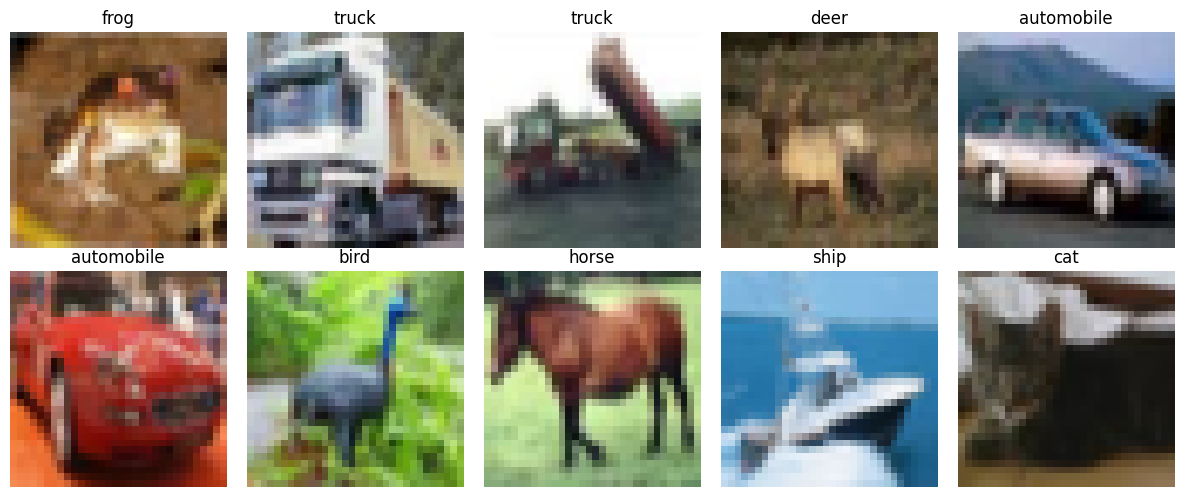

In [2]:
cifar10 = tf.keras.datasets.cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train, x_test = x_train / 255.0, x_test / 255.0

y_train, y_test = y_train.flatten(), y_test.flatten()

K = len(set(y_train))

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("Classes:", K)

labels = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i])
    ax.set_title(labels[y_train[i]])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Arquitetura da CNN

In [3]:
# extracao de caracteristicas (convolucao com stride=2 no lugar de pooling)
i = Input(shape=x_train[0].shape)                                # (32, 32, 3)
x = Conv2D(32, (3, 3), strides=2, activation='relu')(i)          # (15, 15, 32)
x = Conv2D(64, (3, 3), strides=2, activation='relu')(x)          # (7, 7, 64)
x = Conv2D(128, (3, 3), strides=2, activation='relu')(x)         # (3, 3, 128)

x = Flatten()(x)                                                 # (1152,)

# classificacao
x = Dropout(0.5)(x)
x = Dense(1024, activation='relu')(x)                            # (1024,)
x = Dropout(0.2)(x)
x = Dense(K, activation='softmax')(x)                            # (10,)

model = Model(i, x)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 15, 15, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,180,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,284,170 (4.90 MB)

 Trainable params: 1,284,170 (4.90 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Compilação e Treinamento

In [4]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

r = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=15
)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 38ms/step - accuracy: 0.4207 - loss: 1.5898 - val_accuracy: 0.5332 - val_loss: 1.2692
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.5353 - loss: 1.2935 - val_accuracy: 0.5733 - val_loss: 1.1727
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.5877 - loss: 1.1551 - val_accuracy: 0.6255 - val_loss: 1.0547
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 85s 38ms/step - accuracy: 0.6211 - loss: 1.0627 - val_accuracy: 0.6535 - val_loss: 0.9973
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.6480 - loss: 0.9902 - val_accuracy: 0.6687 - val_loss: 0.9439
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.6710 - loss: 0.9297 - val_accuracy: 0.6831 - val_loss: 0.9042
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 36ms/step - accuracy: 0.6856 - loss: 0.8839 - val_accuracy: 0.6801 - val_loss: 0.9128
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 38ms/step - accuracy: 0.7007 -

## 4. Avaliação

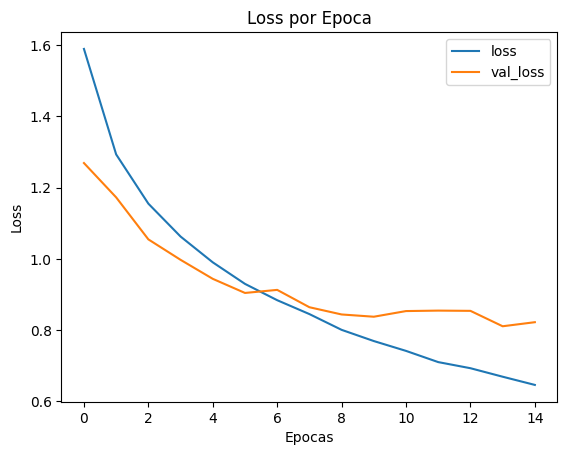

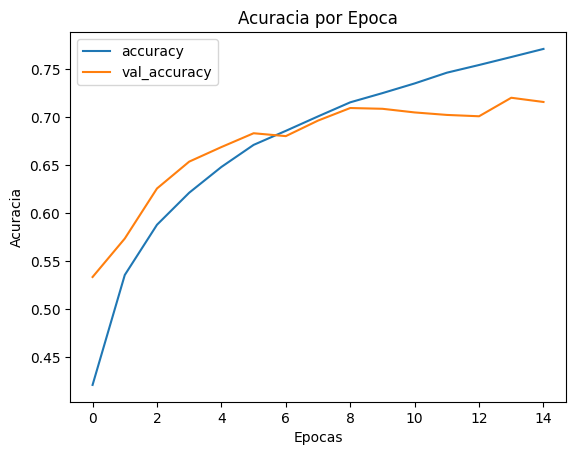

In [5]:
# curva de Loss
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.xlabel('Epocas')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss por Epoca')
plt.show()

# curva de Acuracia
plt.plot(r.history['accuracy'], label='accuracy')
plt.plot(r.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epocas')
plt.ylabel('Acuracia')
plt.legend()
plt.title('Acuracia por Epoca')
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


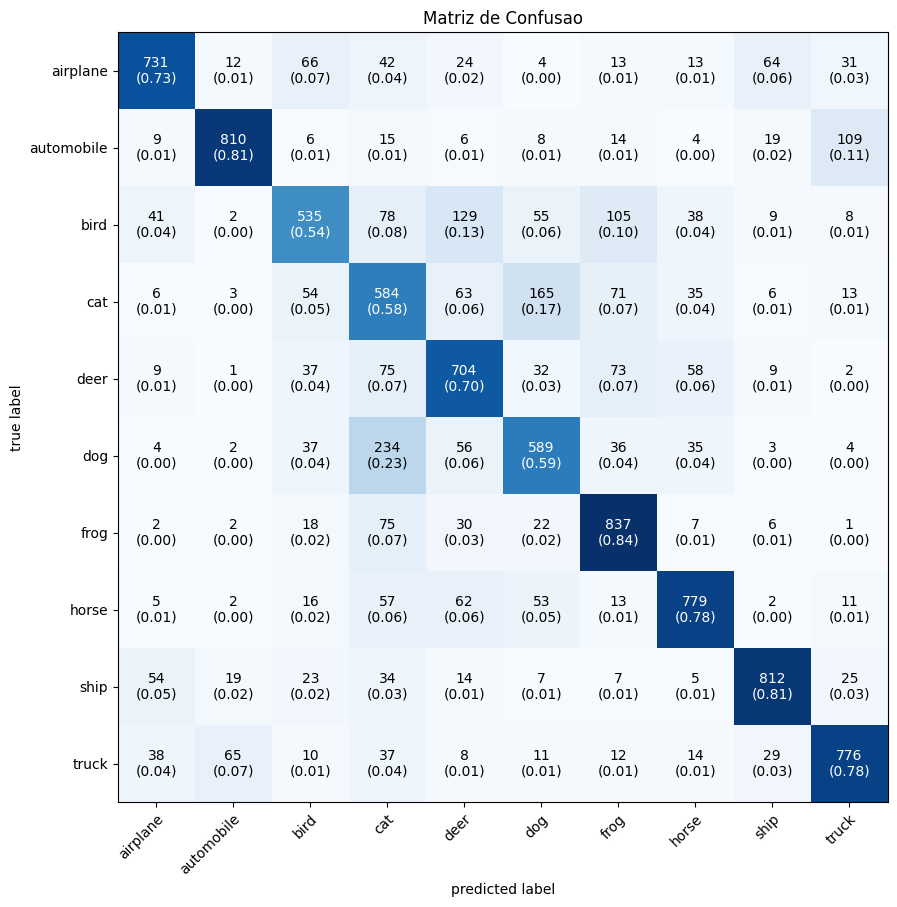

Acuracia no teste: 0.7157


In [6]:
# predicoes
y_pred = model.predict(x_test).argmax(axis=1)

# matriz de confusao
cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(conf_mat=cm, figsize=(10, 10), show_normed=True,
                      class_names=labels)
plt.title('Matriz de Confusao')
plt.show()

print(f'Acuracia no teste: {(y_pred == y_test).mean():.4f}')

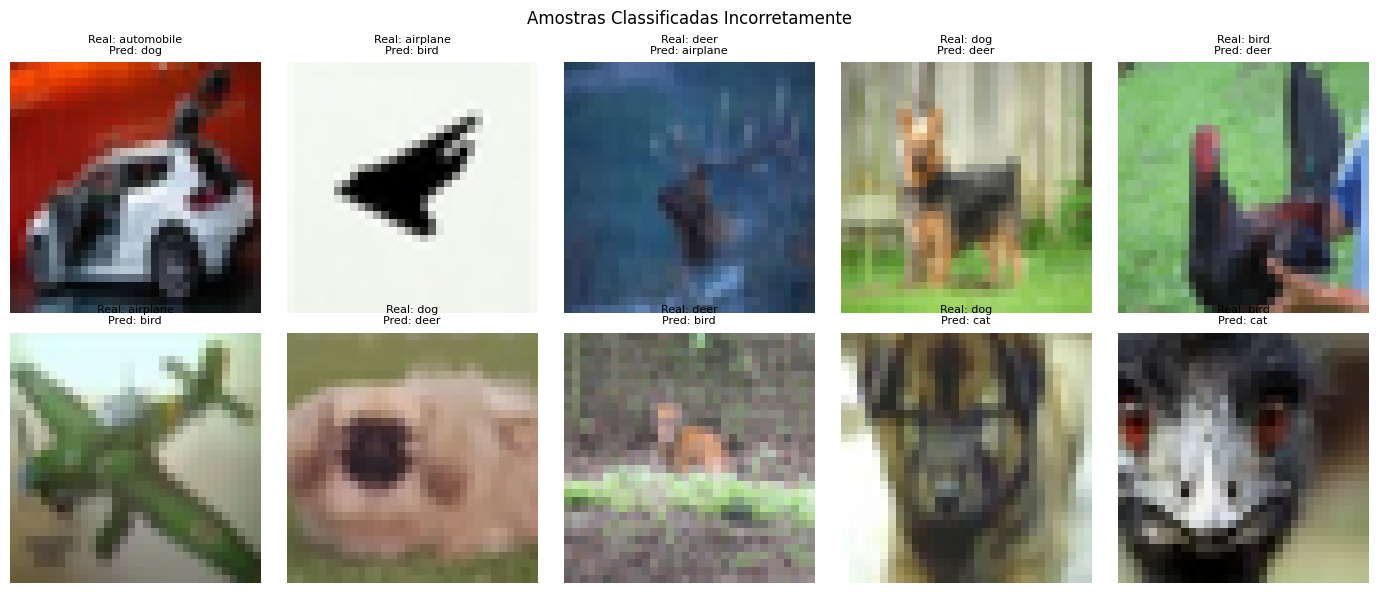

In [7]:
# visualizar imagens classificadas incorretamente
misclassified = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.flat, misclassified[:10]):
    ax.imshow(x_test[idx])
    ax.set_title(f'Real: {labels[y_test[idx]]}\nPred: {labels[y_pred[idx]]}', fontsize=8)
    ax.axis('off')
plt.suptitle('Amostras Classificadas Incorretamente')
plt.tight_layout()
plt.show()